# 💊 Weekly Pharmaceutical Sales Forecasting
**Author:** Sebastian Latiphy

## Project overview
This project explores seasonal sales patterns across eight pharmaceutical categories and evaluates forecasts for **N02BE**, an analgesic and antipyretic category that includes paracetamol.

**Dataset:** 313 weekly observations, January 2018–December 2023. The supplied CSV labels the market as Northeast US and sales volume as Extended Units.

The analysis combines seasonal exploration, candidate feature engineering and a univariate LSTM, benchmarked against ARIMA, Prophet and simple forecasting baselines. The business objective is to identify useful signals for seasonal purchasing and replenishment planning.

## 📦 1. Install & Import Libraries

In [58]:
# Locate the local dataset from either the notebook folder or the IDE workspace.
from pathlib import Path

candidates = [
    Path.cwd() / 'data' / 'iqvia_pharma_sales.csv',
    Path.cwd() / 'forecast-of-drug-pharma-demand-main' / 'data' / 'iqvia_pharma_sales.csv',
]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Cannot find data/iqvia_pharma_sales.csv. Open the notebook from the project folder.'
    )
print(f'Dataset: {DATA_PATH.resolve()}')

Dataset: C:\Users\sebol\Downloads\forecast-of-drug-pharma-demand-main\forecast-of-drug-pharma-demand-main\data\iqvia_pharma_sales.csv


In [59]:
# Run once in your selected notebook kernel, then restart the kernel if prompted.
# %pip installs into the Python environment used by this notebook.
%pip install numpy pandas matplotlib seaborn plotly scikit-learn statsmodels tensorflow prophet ipykernel "nbformat>=4.2.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:
# ── Core Libraries ──
import numpy as np
import pandas as pd
import warnings
# Keep warnings visible so dependency and model issues can be diagnosed.

# ── Visualization ──
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ── Statistics & ML ──
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose

# ── Deep Learning ──
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# ── Prophet ──
from prophet import Prophet

# ── Settings ──
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
sns.set_palette('husl')
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print(f'✅ TensorFlow version: {tf.__version__}')
print('✅ All libraries loaded successfully!')

✅ TensorFlow version: 2.21.0
✅ All libraries loaded successfully!


---
## 📂 2. Load & Explore the Dataset

In [61]:
# Load the supplied local CSV; provenance is not independently verified.
df = pd.read_csv(DATA_PATH)

# Parse date column
df['datum'] = pd.to_datetime(df['datum'])
df = df.sort_values('datum').reset_index(drop=True)
sales_columns = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
if df['datum'].isna().any() or df['datum'].duplicated().any():
    raise ValueError('Dates must be valid and unique.')
if not df['datum'].diff().dropna().eq(pd.Timedelta(days=7)).all():
    raise ValueError('Expected regular weekly observations; inspect gaps before modeling.')
df[sales_columns] = df[sales_columns].apply(pd.to_numeric, errors='raise')
if not np.isfinite(df[sales_columns].to_numpy()).all():
    raise ValueError('Sales contain missing or non-finite values; resolve them before modeling.')
if (df[sales_columns] < 0).any().any():
    raise ValueError('Negative sales require investigation before modeling.')

print(f'📐 Shape: {df.shape}')
print(f'📅 Date Range: {df["datum"].min()} → {df["datum"].max()}')
print(f'🏥 Source label: {df["data_source"].iloc[0]}')
print(f'🌎 Region: {df["region"].iloc[0]}')
print(f'\n🔍 First 5 rows:')
df.head()

📐 Shape: (313, 22)
📅 Date Range: 2018-01-01 00:00:00 → 2023-12-25 00:00:00
🏥 Source label: IQVIA MIDAS
🌎 Region: Northeast US

🔍 First 5 rows:


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,region,...,units,data_source,M01AB_value_usd,M01AE_value_usd,N02BA_value_usd,N02BE_value_usd,N05B_value_usd,N05C_value_usd,R03_value_usd,R06_value_usd
0,2018-01-01,14966.570,35146.270,23705.430,52374.730,10707.400,9127.410,9906.270,10519.640,Northeast US,...,Extended Units,IQVIA MIDAS,127216.000,182761.000,97192.000,356148.000,132772.000,129609.000,282329.000,97833.000
1,2018-01-08,16117.150,40481.340,28093.010,57653.580,13135.740,10279.370,12045.220,12498.920,Northeast US,...,Extended Units,IQVIA MIDAS,136996.000,210503.000,115181.000,392044.000,162883.000,145967.000,343289.000,116240.000
2,2018-01-15,16908.740,39546.160,29208.570,65380.040,13669.750,10545.220,13697.000,10369.310,Northeast US,...,Extended Units,IQVIA MIDAS,143724.000,205640.000,119755.000,444584.000,169505.000,149742.000,390364.000,96435.000
3,2018-01-22,17796.870,41916.710,31413.620,66801.530,12608.420,9838.170,14748.760,11471.100,Northeast US,...,Extended Units,IQVIA MIDAS,151273.000,217967.000,128796.000,454250.000,156344.000,139702.000,420340.000,106681.000
4,2018-01-29,16763.890,41529.150,28888.940,66841.410,14083.200,10299.970,13795.680,11102.070,Northeast US,...,Extended Units,IQVIA MIDAS,142493.000,215952.000,118445.000,454522.000,174632.000,146260.000,393177.000,103249.000


In [62]:
# Broad category descriptions; examples are illustrative, not the measured product mix.
drug_info = {
    'M01AB': 'Anti-inflammatory (e.g. Diclofenac) — Pain & inflammation',
    'M01AE': 'Anti-inflammatory (e.g. Ibuprofen) — OTC pain relief',
    'N02BA': 'Analgesics (e.g. Aspirin) — Pain, fever, cardiovascular',
    'N02BE': 'Analgesics (e.g. Paracetamol) — Analgesics and antipyretics',
    'N05B':  'Anxiolytics (e.g. Diazepam) — Anxiety & sedation',
    'N05C':  'Hypnotics/Sedatives — Sleep disorders',
    'R03':   'Respiratory drugs (e.g. Salbutamol) — Asthma/COPD',
    'R06':   'Antihistamines (e.g. Loratadine) — Allergies'
}

print('💊 Drug Category Reference (ATC Classification System):\n')
for code, desc in drug_info.items():
    print(f'  {code:8} → {desc}')

💊 Drug Category Reference (ATC Classification System):

  M01AB    → Anti-inflammatory (e.g. Diclofenac) — Pain & inflammation
  M01AE    → Anti-inflammatory (e.g. Ibuprofen) — OTC pain relief
  N02BA    → Analgesics (e.g. Aspirin) — Pain, fever, cardiovascular
  N02BE    → Analgesics (e.g. Paracetamol) — Analgesics and antipyretics
  N05B     → Anxiolytics (e.g. Diazepam) — Anxiety & sedation
  N05C     → Hypnotics/Sedatives — Sleep disorders
  R03      → Respiratory drugs (e.g. Salbutamol) — Asthma/COPD
  R06      → Antihistamines (e.g. Loratadine) — Allergies


In [63]:
# ── Basic Statistics ──
from IPython.display import display

if 'df' not in globals():
    raise RuntimeError('Run the Load & Explore the Dataset cell first to create df.')

print('📊 Descriptive Statistics (numeric columns):\n')
numeric_data = df.select_dtypes(include='number')
if numeric_data.empty:
    raise ValueError('No numeric columns found. Check the CSV loading and column types.')
display(numeric_data.describe().round(2))

print(f'\n📅 Date range: {df["datum"].min()} → {df["datum"].max()}')
print(f'📐 Observations: {len(df):,}')

📊 Descriptive Statistics (numeric columns):



,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,M01AB_value_usd,M01AE_value_usd,N02BA_value_usd,N02BE_value_usd,N05B_value_usd,N05C_value_usd,R03_value_usd,R06_value_usd
count,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000,313.000
mean,18859.200,43785.860,30291.320,71109.240,12102.670,9127.710,14805.520,16542.730,160303.210,227686.510,124194.400,483542.850,150073.040,129613.510,421957.180,153847.410
std,2821.210,9614.640,6568.930,16034.960,1719.030,1323.320,3158.550,3797.700,23980.270,49996.140,26932.600,109037.700,21315.950,18791.140,90018.690,35318.640
min,13691.340,28310.410,19328.310,47527.890,8029.220,5869.820,9393.280,8969.360,116376.000,147214.000,79246.000,323190.000,99562.000,83351.000,267708.000,83415.000
25%,16775.060,35273.910,24509.910,57178.490,11016.380,8308.270,12486.100,13322.380,142588.000,183424.000,100491.000,388814.000,136603.000,117977.000,355854.000,123898.000
50%,18533.200,41916.710,29753.570,68261.570,11911.320,8988.290,14761.860,16220.410,157532.000,217967.000,121990.000,464179.000,147700.000,127634.000,420713.000,150850.000
75%,20867.190,51393.270,35374.170,83486.740,13104.940,9862.240,16598.260,20034.760,177371.000,267245.000,145034.000,567710.000,162501.000,140044.000,473050.000,186323.000
max,30751.610,77931.850,55444.750,128659.480,19829.760,15446.910,27718.950,24691.900,261389.000,405246.000,227323.000,874884.000,245889.000,219346.000,789990.000,229635.000



📅 Date range: 2018-01-01 00:00:00 → 2023-12-25 00:00:00
📐 Observations: 313


In [64]:
# ── Missing Value Check ──
if 'df' not in globals():
    raise RuntimeError('Run the Load & Explore the Dataset cell first to create df.')

print('🔍 Missing Values:')
missing = df.isna().sum()
print(missing.to_string())
total_missing = int(missing.sum())
if total_missing == 0:
    print('\n✅ No missing values found.')
else:
    print(f'\n⚠️ Total missing values: {total_missing:,}. Review these before modeling.')

🔍 Missing Values:
datum              0
M01AB              0
M01AE              0
N02BA              0
N02BE              0
N05B               0
N05C               0
R03                0
R06                0
region             0
channel            0
currency           0
units              0
data_source        0
M01AB_value_usd    0
M01AE_value_usd    0
N02BA_value_usd    0
N02BE_value_usd    0
N05B_value_usd     0
N05C_value_usd     0
R03_value_usd      0
R06_value_usd      0

✅ No missing values found.


---
## 📊 3. Exploratory Data Analysis (EDA)

In [65]:
# ── 3.1 Sales Trend for All Drug Categories ──
drug_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

fig = make_subplots(rows=4, cols=2,
                    subplot_titles=[f'{col} — {drug_info[col].split("(")[0].strip()}' for col in drug_cols],
                    vertical_spacing=0.08)

colors = ['#636EFA','#EF553B','#00CC96','#AB63FA','#FFA15A','#19D3F3','#FF6692','#B6E880']

for i, col in enumerate(drug_cols):
    row = i // 2 + 1
    c = i % 2 + 1
    fig.add_trace(
        go.Scatter(x=df['datum'], y=df[col], name=col,
                   line=dict(color=colors[i], width=1.5)),
        row=row, col=c
    )

fig.update_layout(
    title='💊 Weekly Drug Sales — All Categories (6-Year Trend)',
    height=900, showlegend=False,
    template='plotly_dark'
)
fig.show(renderer="vscode")


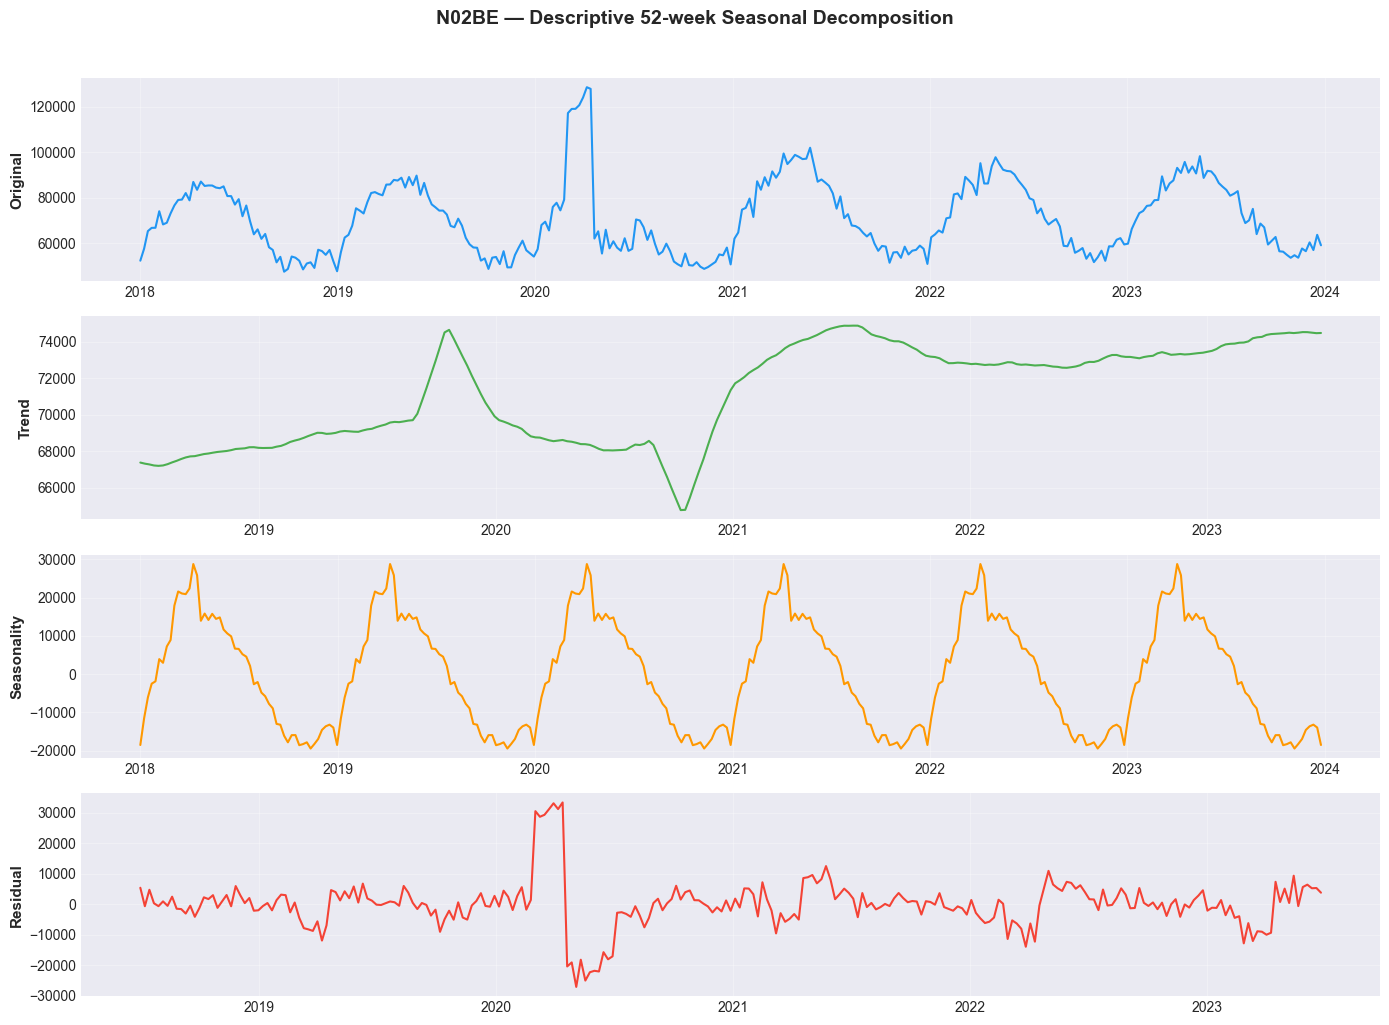

Descriptive decomposition only: monthly summaries below locate the peaks; their cause is not identified.


In [66]:
# ── 3.2 Seasonal Decomposition (Focus: N02BE - Paracetamol) ──
# Descriptive additive decomposition: a 52-week cycle approximates a calendar year.
# The method imposes a repeating seasonal component; it does not prove causality.

ts = df.set_index('datum')['N02BE']
decomp = seasonal_decompose(ts, model='additive', period=52)  # 52 weeks = 1 year

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
fig.suptitle('N02BE — Descriptive 52-week Seasonal Decomposition', fontsize=14, fontweight='bold', y=1.02)

components = [('Original', decomp.observed, '#2196F3'),
              ('Trend', decomp.trend, '#4CAF50'),
              ('Seasonality', decomp.seasonal, '#FF9800'),
              ('Residual', decomp.resid, '#F44336')]

for ax, (label, data, color) in zip(axes, components):
    ax.plot(data, color=color, linewidth=1.5)
    ax.set_ylabel(label, fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('Descriptive decomposition only: monthly summaries below locate the peaks; their cause is not identified.')

C:\Users\sebol\AppData\Local\Temp\ipykernel_568\1015143968.py:20: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\sebol\AppData\Local\Temp\ipykernel_568\1015143968.py:20: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\sebol\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\sebol\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


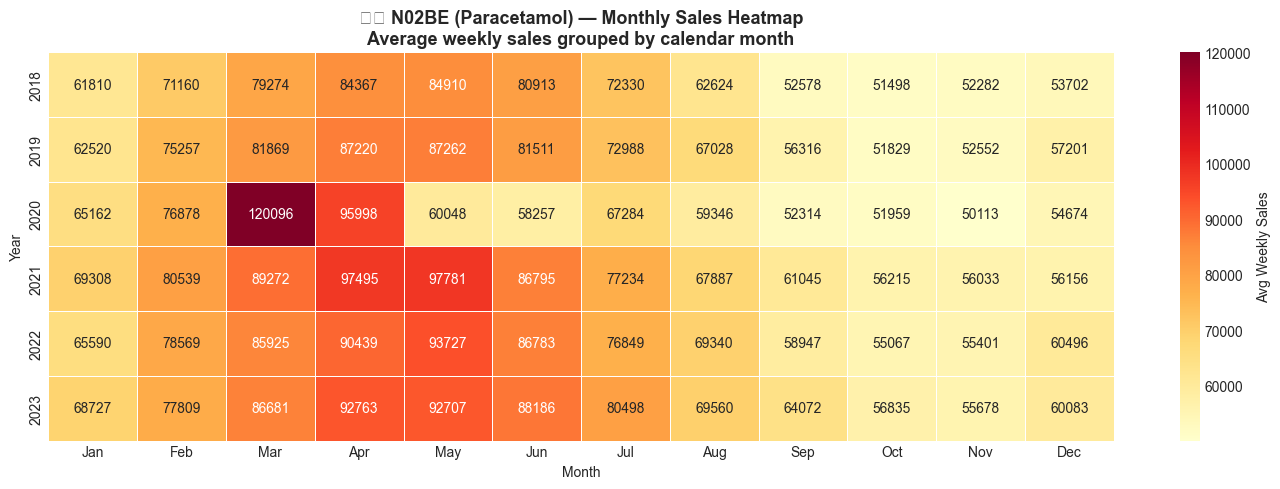

,Mean weekly sales
month,
Jan,65503.552
Feb,76702.224
Mar,91609.007
Apr,90950.603
May,87035.203
Jun,79521.372
Jul,74612.893
Aug,65915.166
Sep,57496.193


,Peak month,Nov–Feb mean weekly sales,Mar–May mean weekly sales
year,,,
2018,May,59518.272,82967.172
2019,May,61606.974,85586.548
2020,Mar,61024.855,94204.725
2021,May,64951.824,94660.295
2022,May,65047.922,90314.558
2023,Apr,65759.570,90869.782


In the supplied CSV, peaks occur in March–May, not November–February. These summaries do not establish a flu, allergy or other clinical cause.


In [67]:
# ── 3.3 Monthly Seasonality Heatmap ──
df['year'] = df['datum'].dt.year
df['month'] = df['datum'].dt.month
df['week'] = df['datum'].dt.isocalendar().week.astype(int)
df['quarter'] = df['datum'].dt.quarter

month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

pivot = df.groupby(['year', 'month'])['N02BE'].mean().unstack()
pivot = pivot.reindex(columns=range(1, 13))
pivot.columns = month_names

plt.figure(figsize=(14, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Avg Weekly Sales'})
plt.title('🌡️ N02BE (Paracetamol) — Monthly Sales Heatmap\nAverage weekly sales grouped by calendar month', 
          fontsize=13, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

# Calculate observations rather than assigning a clinical explanation.
monthly_means = df.groupby('month')['N02BE'].mean().reindex(range(1, 13))
display(monthly_means.rename(index=dict(enumerate(month_names, start=1))).to_frame('Mean weekly sales'))
annual_summary = df.groupby(['year', 'month'])['N02BE'].mean().unstack().reindex(columns=range(1, 13))
display(pd.DataFrame({
    'Peak month': annual_summary.idxmax(axis=1).map(dict(enumerate(month_names, start=1))),
    'Nov–Feb mean weekly sales': df[df['month'].isin([11, 12, 1, 2])].groupby('year')['N02BE'].mean(),
    'Mar–May mean weekly sales': df[df['month'].isin([3, 4, 5])].groupby('year')['N02BE'].mean(),
}))
print('In the supplied CSV, peaks occur in March–May, not November–February. These summaries do not establish a flu, allergy or other clinical cause.')

C:\Users\sebol\AppData\Local\Temp\ipykernel_568\3983412773.py:11: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\sebol\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


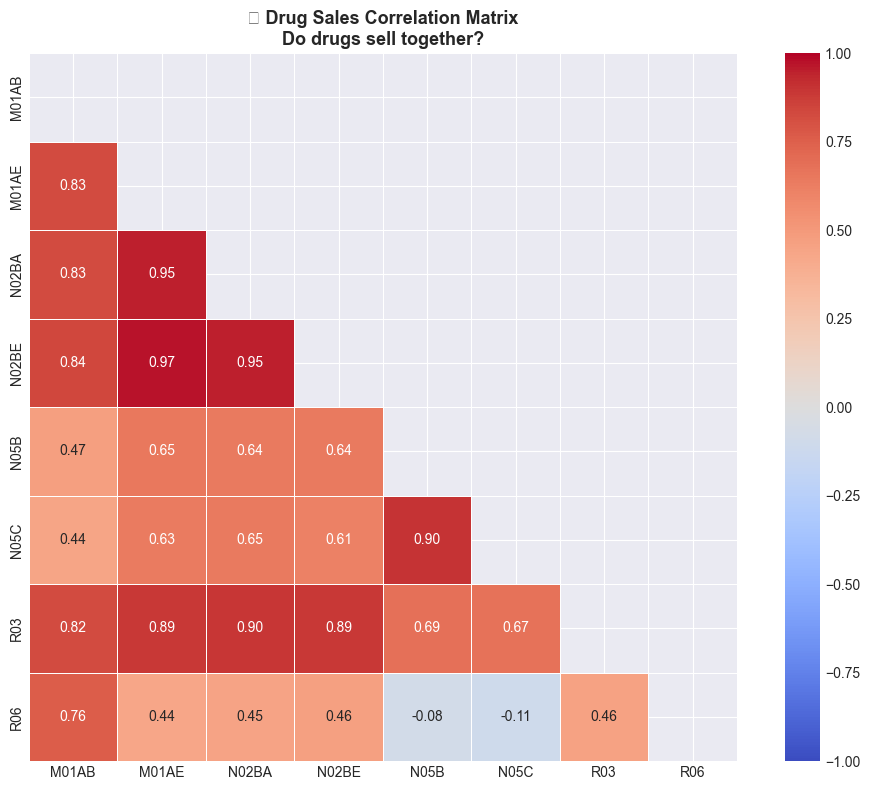

N02BA/N02BE Pearson correlation: 0.949.
The categories co-move in aggregate. Shared trends and seasonality can contribute; patient switching, causality and predictive improvement are not established.


In [68]:
# ── 3.4 Correlation Matrix ──
plt.figure(figsize=(10, 8))
corr = df[drug_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title('🔗 Drug Sales Correlation Matrix\nDo drugs sell together?', 
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'N02BA/N02BE Pearson correlation: {corr.loc["N02BA", "N02BE"]:.3f}.')
print('The categories co-move in aggregate. Shared trends and seasonality can contribute; patient switching, causality and predictive improvement are not established.')

In [69]:
# ── 3.5 Total Sales Distribution by Drug ──
total_sales = df[drug_cols].sum().sort_values(ascending=False)

fig = px.bar(x=total_sales.index, y=total_sales.values,
             color=total_sales.values,
             color_continuous_scale='Viridis',
             labels={'x': 'Drug Category', 'y': 'Total Sales (6 Years)'},
             title='💰 Total Sales Volume by Drug Category (6-Year Period)',
             template='plotly_dark')

for i, (drug, val) in enumerate(zip(total_sales.index, total_sales.values)):
    fig.add_annotation(x=drug, y=val, text=f'{val:,.0f}',
                       showarrow=False, yshift=15, font=dict(size=11))

fig.update_layout(height=500, showlegend=False)
fig.show(renderer="vscode")

In [70]:
# ADF null hypothesis: a unit root, with a constant and AIC-selected lag length.
adf_results = []
for col in drug_cols:
    statistic, p_value, used_lag, nobs, critical, *rest = adfuller(df[col], regression='c', autolag='AIC')
    adf_results.append({'Category': col, 'ADF statistic': statistic, 'p-value': p_value,
                        'Lags': used_lag, 'Reject unit-root null at 5%': p_value < 0.05})
display(pd.DataFrame(adf_results))
print('Rejection is evidence against this unit-root null, not proof of all stationarity assumptions. Non-rejection is inconclusive. Differencing and seasonal structure require training-only diagnostics and validation; eight exploratory tests are not adjusted for multiplicity.')

C:\Users\sebol\AppData\Local\Temp\ipykernel_568\3350997728.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, used_lag, nobs, critical, *rest = adfuller(df[col], regression='c', autolag='AIC')
C:\Users\sebol\AppData\Local\Temp\ipykernel_568\3350997728.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, used_lag, nobs, critical, *re

,Category,ADF statistic,p-value,Lags,Reject unit-root null at 5%
0,M01AB,-4.979,0.000,6,True
1,M01AE,-4.732,0.000,6,True
2,N02BA,-4.337,0.000,7,True
3,N02BE,-5.065,0.000,13,True
4,N05B,-4.762,0.000,9,True
5,N05C,-5.177,0.000,6,True
6,R03,-4.720,0.000,7,True
7,R06,-4.928,0.000,6,True


Rejection is evidence against this unit-root null, not proof of all stationarity assumptions. Non-rejection is inconclusive. Differencing and seasonal structure require training-only diagnostics and validation; eight exploratory tests are not adjusted for multiplicity.


## 🔧 4. Candidate features
Calendar, lag and rolling features provide candidates for a future multivariate model. Rolling statistics and cross-category signals use past observations so they are available at the forecast date.

The LSTM in this study uses **26 previous N02BE sales observations**. Candidate features are explored separately; their contribution to forecast accuracy has not been evaluated.

In [71]:
# N02BE is the target sales category; paracetamol is an example within it.
TARGET = 'N02BE'

# Keep only numeric drug columns + datum
drug_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']
df_feat = df[['datum'] + drug_cols].copy()
candidate_features = df_feat.copy()

# ── Time Features ──
candidate_features['week_of_year']   = candidate_features['datum'].dt.isocalendar().week.astype(int)
candidate_features['month']          = candidate_features['datum'].dt.month
candidate_features['quarter']        = candidate_features['datum'].dt.quarter
candidate_features['year']           = candidate_features['datum'].dt.year

# ── Cyclical Encoding ──
candidate_features['month_sin']  = np.sin(2 * np.pi * candidate_features['month'] / 12)
candidate_features['month_cos']  = np.cos(2 * np.pi * candidate_features['month'] / 12)
candidate_features['week_sin']   = np.sin(2 * np.pi * candidate_features['week_of_year'] / 52)
candidate_features['week_cos']   = np.cos(2 * np.pi * candidate_features['week_of_year'] / 52)

# ── Lag Features ──
for lag in [1, 2, 4, 8, 13, 26, 52]:
    candidate_features[f'lag_{lag}'] = candidate_features[TARGET].shift(lag)

# ── Rolling Statistics ──
for window in [4, 8, 13, 26]:
    candidate_features[f'rolling_mean_{window}'] = candidate_features[TARGET].shift(1).rolling(window).mean()
    candidate_features[f'rolling_std_{window}']  = candidate_features[TARGET].shift(1).rolling(window).std()

# ── Pharma Domain Features ──
candidate_features['is_nov_to_feb']     = candidate_features['month'].isin([11, 12, 1, 2]).astype(int)
candidate_features['is_mar_to_may'] = candidate_features['month'].isin([3, 4, 5]).astype(int)
candidate_features['is_summer']         = candidate_features['month'].isin([6, 7, 8]).astype(int)
candidate_features['is_year_end']       = (candidate_features['month'] == 12).astype(int)
candidate_features['analgesic_combo']   = (candidate_features['N02BA'] + candidate_features['M01AB'] + candidate_features['M01AE']).shift(1)

# Keep missing warm-up lags in candidates; they are not used in this model.

print(f'Univariate modeling rows: {len(df_feat)}; candidate columns: {candidate_features.shape[1] - 2}')
print('LSTM input features: one (past N02BE sales). Candidate features are unused.')

Univariate modeling rows: 313; candidate columns: 35
LSTM input features: one (past N02BE sales). Candidate features are unused.


## 🤖 5. Univariate LSTM
Chronological sequences are split 80/20 into pre-test and test targets. The last 15% of pre-test sequences form a chronological validation block for epoch selection. The scaler is fitted only on the earlier fitting block. The selected epoch count is then used to refit a fresh LSTM on all pre-test sequences; test values are never used for scaling or fitting.

Overlapping windows contain historical observations available at each forecast origin. The one-step diagnostic updates inputs with observed prior test sales. The model comparison instead recursively forecasts from one common origin with no test observations supplied to any model. Fixed hyperparameters and one validation block limit the evidence.

In [72]:
SEQUENCE_LENGTH = 26  # Illustrative 26-week history; not an optimized choice.
TRAIN_RATIO = 0.80
series = df_feat[TARGET].to_numpy(dtype=float).reshape(-1, 1)
split = int((len(series) - SEQUENCE_LENGTH) * TRAIN_RATIO)
validation_start = int(split * 0.85)
test_start = split + SEQUENCE_LENGTH
fit_end = validation_start + SEQUENCE_LENGTH

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(series[:fit_end])
series_scaled = scaler.transform(series)

def create_sequences(data, seq_len):
    X = np.array([data[i-seq_len:i, 0] for i in range(seq_len, len(data))])
    y = data[seq_len:, 0]
    return X.reshape(-1, seq_len, 1), y

X, y = create_sequences(series_scaled, SEQUENCE_LENGTH)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
X_fit, X_val = X_train[:validation_start], X_train[validation_start:]
y_fit, y_val = y_train[:validation_start], y_train[validation_start:]
test_dates = df_feat['datum'].iloc[test_start:].to_numpy()
print(f'Fitting / validation / test sequences: {len(X_fit)} / {len(X_val)} / {len(X_test)}')
print(f'Test origin: {df_feat["datum"].iloc[test_start - 1]}; first test date: {test_dates[0]}')
assert len(test_dates) == len(y_test)
assert fit_end < test_start

Fitting / validation / test sequences: 194 / 35 / 58
Test origin: 2022-11-14 00:00:00; first test date: 2022-11-21T00:00:00.000000


In [73]:
def build_lstm():
    return Sequential([
        tf.keras.Input(shape=(SEQUENCE_LENGTH, 1)),
        LSTM(64, return_sequences=True), Dropout(0.2),
        LSTM(32), Dropout(0.2),
        Dense(16, activation='relu'), Dense(1)
    ], name='Pharma_LSTM')

def compile_lstm(model):
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

tf.keras.utils.set_random_seed(42)
model = build_lstm()
compile_lstm(model)
model.summary()

Model: "Pharma_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_14 (LSTM)                  │ (None, 26, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 26, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
callbacks = [EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True, verbose=1)]
history = model.fit(X_fit, y_fit, epochs=200, batch_size=16,
                    validation_data=(X_val, y_val), shuffle=False,
                    callbacks=callbacks, verbose=1)
best_epochs = int(np.argmin(history.history['val_loss']) + 1)
print(f'Validation-selected training duration: {best_epochs} epochs.')

# Refit from scratch on all pre-test observations using that fixed duration.
tf.keras.utils.set_random_seed(42)
model = build_lstm()
compile_lstm(model)
model.fit(X_train, y_train, epochs=best_epochs, batch_size=16, shuffle=False, verbose=0)
print('Evaluation model refitted on pre-test sequences; test period remains excluded.')

Epoch 1/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0706 - mae: 0.1932 - val_loss: 0.0368 - val_mae: 0.1761
Epoch 2/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0478 - mae: 0.1808 - val_loss: 0.0261 - val_mae: 0.1450
Epoch 3/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0402 - mae: 0.1538 - val_loss: 0.0228 - val_mae: 0.1334
Epoch 4/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0349 - mae: 0.1463 - val_loss: 0.0177 - val_mae: 0.1185
Epoch 5/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0316 - mae: 0.1379 - val_loss: 0.0120 - val_mae: 0.0917
Epoch 6/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0249 - mae: 0.1148 - val_loss: 0.0044 - val_mae: 0.0569
Epoch 7/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0295 - mae: 0.1306 - val_loss: 0.0018 - val_mae: 0.0352
Epoch 8/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0251 - mae: 0.1175 - val_loss: 0.0099 - val_mae: 0.0808
Epoch 9/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - lo

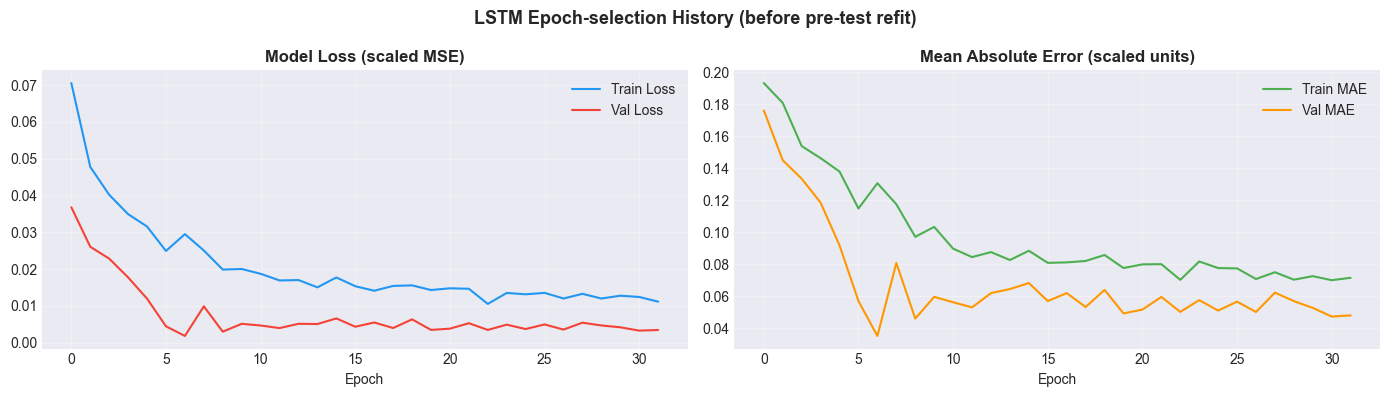

In [75]:
# ── 5.4 Training History Plot ──
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(history.history['loss'], label='Train Loss', color='#2196F3')
ax1.plot(history.history['val_loss'], label='Val Loss', color='#F44336')
ax1.set_title('Model Loss (scaled MSE)', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['mae'], label='Train MAE', color='#4CAF50')
ax2.plot(history.history['val_mae'], label='Val MAE', color='#FF9800')
ax2.set_title('Mean Absolute Error (scaled units)', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('LSTM Epoch-selection History (before pre-test refit)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [76]:
def metric_row(name, actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    nonzero = actual != 0
    return {'Model': name, 'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R²': r2_score(actual, predicted),
            'MAPE (%)': np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan}

y_pred = scaler.inverse_transform(model.predict(X_test, verbose=0)).ravel()
y_actual = series[test_start:, 0]
lstm_one_step_metrics = metric_row('LSTM: observed-history one-step diagnostic', y_actual, y_pred)
display(pd.DataFrame([lstm_one_step_metrics]))
print('These one-step scores are separate from the fixed-origin comparison below. MAPE excludes zero actuals; R² is not a percentage accuracy.')

def recursive_forecast(fitted_model, fitted_scaler, history_values, steps):
    sequence = fitted_scaler.transform(np.asarray(history_values).reshape(-1, 1))[-SEQUENCE_LENGTH:].reshape(1, SEQUENCE_LENGTH, 1)
    predictions = []
    for _ in range(steps):
        value = float(fitted_model(sequence, training=False).numpy()[0, 0])
        predictions.append(value)
        sequence = np.concatenate([sequence[:, 1:, :], np.array([[[value]]])], axis=1)
    return fitted_scaler.inverse_transform(np.array(predictions).reshape(-1, 1)).ravel()

lstm_fixed_pred = recursive_forecast(model, scaler, series[:test_start, 0], len(y_actual))

,Model,MAE,RMSE,R²,MAPE (%)
0,LSTM: observed-history one-step diagnostic,3153.175,3888.368,0.920,4.537


These one-step scores are separate from the fixed-origin comparison below. MAPE excludes zero actuals; R² is not a percentage accuracy.


In [77]:
# ── 5.6 Actual vs Predicted Plot ──
test_dates = df_feat['datum'].values[split + SEQUENCE_LENGTH:]

fig = go.Figure()
fig.add_trace(go.Scatter(x=test_dates, y=y_actual,
                          name='Actual Sales',
                          line=dict(color='#2196F3', width=2)))
fig.add_trace(go.Scatter(x=test_dates, y=y_pred,
                          name='LSTM observed-history one-step',
                          line=dict(color='#FF5722', width=2, dash='dot')))

fig.update_layout(
    title=f'LSTM One-step Diagnostic | R² = {lstm_one_step_metrics["R²"]:.4f}',
    xaxis_title='Date',
    yaxis_title='Weekly Sales',
    template='plotly_dark',
    height=450
)
fig.show(renderer="vscode")

## 📈 6. Matched fixed-origin comparison
Every model uses the same pre-test observations and predicts the same Monday test dates without receiving test-period sales. The LSTM uses recursive predictions; ARIMA and Prophet forecast from the same cutoff. Persistence repeats the last observation; seasonal-naive repeats the preceding 52-week cycle (an approximate annual baseline).

The tables show the full holdout and the first 12 weeks from that origin. These are **one-origin** evaluations, not evidence of performance over many origins or statistical superiority. ARIMA(2,1,2) is an untuned, nonseasonal baseline; other ARIMA orders and seasonal models may perform differently.

In [78]:
train_arima = series[:test_start, 0]
test_arima = y_actual
arima_fit = ARIMA(train_arima, order=(2, 1, 2)).fit()
arima_pred = np.asarray(arima_fit.forecast(steps=len(y_actual)))
print('ARIMA(2,1,2): fixed-origin forecast, no test observations supplied.')

ARIMA(2,1,2): fixed-origin forecast, no test observations supplied.


In [79]:
df_prophet = df_feat[['datum', TARGET]].rename(columns={'datum': 'ds', TARGET: 'y'})
train_prophet = df_prophet.iloc[:test_start]
test_prophet = df_prophet.iloc[test_start:]
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                        daily_seasonality=False, changepoint_prior_scale=0.05)
prophet_model.fit(train_prophet)
# Predict at the actual held-out dates, avoiding Sunday/Monday misalignment.
forecast = prophet_model.predict(test_prophet[['ds']])
assert np.array_equal(forecast['ds'].to_numpy(), test_dates)
prophet_pred = forecast['yhat'].to_numpy()

19:27:58 - cmdstanpy - INFO - Chain [1] start processing
19:27:58 - cmdstanpy - INFO - Chain [1] done processing


In [80]:
persistence_pred = np.repeat(train_arima[-1], len(y_actual))
seasonal_naive_pred = np.array([train_arima[len(train_arima) - 52 + (i % 52)] for i in range(len(y_actual))])
fixed_predictions = {'Persistence': persistence_pred, 'Seasonal naive (52 weeks)': seasonal_naive_pred,
                     'ARIMA(2,1,2)': arima_pred, 'Prophet': prophet_pred, 'LSTM recursive': lstm_fixed_pred}
results = pd.DataFrame([metric_row(name, y_actual, pred) for name, pred in fixed_predictions.items()])
first_12_results = pd.DataFrame([metric_row(name, y_actual[:12], pred[:12]) for name, pred in fixed_predictions.items()])
print('Full holdout: matched fixed-origin evaluation')
display(results.sort_values('MAE').reset_index(drop=True))
print('First 12 weeks: same origin, shorter horizon')
display(first_12_results.sort_values('MAE').reset_index(drop=True))
print('Lowest error on this origin is descriptive, not proof of a universally best model. Model settings were not systematically optimized.')

Full holdout: matched fixed-origin evaluation


,Model,MAE,RMSE,R²,MAPE (%)
0,Prophet,3551.134,4596.433,0.888,4.768
1,Seasonal naive (52 weeks),3617.887,4434.821,0.896,5.076
2,LSTM recursive,6299.634,7631.701,0.692,9.160
3,"ARIMA(2,1,2)",16611.553,21154.740,-1.364,20.216
4,Persistence,16644.308,21190.713,-1.372,20.257


First 12 weeks: same origin, shorter horizon


,Model,MAE,RMSE,R²,MAPE (%)
0,Prophet,1639.275,2065.981,0.918,2.640
1,LSTM recursive,2612.263,3558.615,0.757,4.399
2,Seasonal naive (52 weeks),4041.085,4637.211,0.587,6.210
3,"ARIMA(2,1,2)",8384.795,10506.279,-1.118,12.182
4,Persistence,8415.726,10536.641,-1.130,12.229


Lowest error on this origin is descriptive, not proof of a universally best model. Model settings were not systematically optimized.


In [81]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=test_dates, y=y_actual, name='Actual', line=dict(color='white', width=3)))
for name, predictions in fixed_predictions.items():
    fig.add_trace(go.Scatter(x=test_dates, y=predictions, name=name))
fig.update_layout(title='Matched Fixed-origin Forecasts — No Test Sales Used as Inputs',
                  xaxis_title='Date', yaxis_title='Weekly sales (Extended Units)',
                  template='plotly_dark', height=500)
fig.show(renderer='vscode')

## 🔮 7. Twelve-week sales projection
A separate LSTM is fitted on all available history using the validation-selected training duration. It generates recursive weekly projections for **2024-01-01 to 2024-03-18**, immediately after the dataset ends.

These point projections illustrate the forecasting workflow. Forecast uncertainty and performance across several 12-week periods should be evaluated before using them for procurement decisions.

In [82]:
FORECAST_WEEKS = 12
production_scaler = MinMaxScaler().fit(series)
all_scaled = production_scaler.transform(series)
X_all, y_all = create_sequences(all_scaled, SEQUENCE_LENGTH)
tf.keras.utils.set_random_seed(42)
production_model = build_lstm()
compile_lstm(production_model)
production_model.fit(X_all, y_all, epochs=best_epochs, batch_size=16, shuffle=False, verbose=0)
future_preds = recursive_forecast(production_model, production_scaler, series[:, 0], FORECAST_WEEKS)
future_dates = pd.date_range(start=df_feat['datum'].max() + pd.Timedelta(days=7), periods=FORECAST_WEEKS, freq='7D')
fig = go.Figure()
hist = df_feat.tail(52)
fig.add_trace(go.Scatter(x=hist['datum'], y=hist[TARGET], name='Historical sales'))
fig.add_trace(go.Scatter(x=future_dates, y=future_preds, name='Recursive LSTM projection', mode='lines+markers'))
fig.update_layout(title='N02BE — 12-Week Sales Projection',
                  xaxis_title='Date', yaxis_title='Weekly sales (Extended Units)', template='plotly_dark', height=500)
# Mark the first forecast date without adding another legend entry.
forecast_start = future_dates[0].to_pydatetime()
fig.add_shape(type='line', x0=forecast_start, x1=forecast_start,
              y0=0, y1=1, xref='x', yref='paper',
              line=dict(color='#BDBDBD', width=1.5, dash='dash'))
fig.add_annotation(x=forecast_start, y=1, xref='x', yref='paper',
                   text='Forecast begins', showarrow=False,
                   xanchor='left', yanchor='bottom', xshift=8,
                   font=dict(color='#BDBDBD', size=12))
fig.show(renderer='vscode')

from IPython.display import Markdown
display(Markdown(
    '*The recursive LSTM projects rising sales toward spring. These point forecasts '
    'illustrate the expected trajectory; actual weekly sales may fluctuate, '
    'and forecast uncertainty has not been quantified.*'
))
display(pd.DataFrame({'Date': future_dates, 'Projected sales': future_preds}))
if (future_preds < 0).any():
    print('Warning: negative projections are incompatible with nonnegative sales; investigate model suitability.')
print('Point projections only; uncertainty coverage and procurement benefits have not been measured.')

*The recursive LSTM projects rising sales toward spring. These point forecasts illustrate the expected trajectory; actual weekly sales may fluctuate, and forecast uncertainty has not been quantified.*

,Date,Projected sales
0,2024-01-01,64404.596
1,2024-01-08,65869.262
2,2024-01-15,67483.727
3,2024-01-22,69220.838
4,2024-01-29,71032.974
5,2024-02-05,72816.216
6,2024-02-12,74583.778
7,2024-02-19,76336.120
8,2024-02-26,78050.423
9,2024-03-04,79599.021


Point projections only; uncertainty coverage and procurement benefits have not been measured.


## 💾 8. Save model and scaler
Save the all-history forecasting model, its matching scaler and metadata for subsequent inference.

In [83]:
import pickle
production_model.save('pharma_lstm_model.keras')
with open('scaler.pkl', 'wb') as f:
    pickle.dump(production_scaler, f)
metadata = {'target': TARGET, 'sequence_length': SEQUENCE_LENGTH, 'input_features': [TARGET],
            'history_end': str(df_feat['datum'].max().date()), 'training_epochs': best_epochs,
            'forecast_method': 'recursive, no additional seasonal multiplier',
            'tensorflow_version': tf.__version__, 'numpy_version': np.__version__, 'pandas_version': pd.__version__}
import json
with open('forecast_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)
print('Saved all-history model: pharma_lstm_model.keras; scaler.pkl; forecast_metadata.json')

Saved all-history model: pharma_lstm_model.keras; scaler.pkl; forecast_metadata.json


## 🏁 9. Key findings and business recommendations

### Key findings

| Finding | Business implication |
|---|---|
| **Spring sales peak** | N02BE average weekly sales are highest in March–May. Each year's highest monthly average falls within this period, making spring a priority for seasonal purchasing reviews. |
| **Shared category movement** | N02BA and N02BE sales are strongly correlated (Pearson r ≈ 0.949). Monitor category trends together and test whether lagged signals improve forecasts. The correlation does not establish patient substitution. |
| **Forecasting benchmarks** | Compare Prophet, recursive LSTM and ARIMA with persistence and seasonal-naive forecasts at the same forecast origin. Use the evaluation tables to select candidates for further testing at the required planning horizon. |
| **Feature opportunities** | Calendar and cross-category features are candidates for future experiments. The current LSTM uses past N02BE sales only. |

### Business recommendations

- **Prepare purchasing plans ahead of spring.** Review N02BE supplier capacity and delivery schedules before March–May, allowing for procurement lead times. Confirm the seasonal pattern in recent data before changing orders.
- **Set stock levels using operational constraints.** Combine forecasts with on-hand inventory, supplier lead times, service targets and expiry dates. Evaluate a targeted seasonal buffer rather than increasing stock across every category.
- **Choose a model for the decision horizon.** Evaluate Prophet and the seasonal-naive baseline alongside LSTM at 1-, 4- and 12-week horizons. A simple model may offer sufficient accuracy with lower maintenance effort.
- **Refresh forecasts as sales arrive.** Track forecast errors weekly and revise purchasing plans when actual sales diverge from expectations.
- **Measure value in a replenishment pilot.** Compare service levels, stockout days, expiry waste and inventory costs with the existing planning process before wider adoption.

### Scope and next steps

These findings concern historical sales in the supplied dataset. Sales may be constrained by stock availability, and seasonal summaries do not identify clinical causes. One forecast origin provides limited evidence of future performance; inventory savings have not been measured.

Extend the evaluation to recent data and multiple forecast origins, test candidate features, and estimate prediction intervals. Use those results to assess whether forecast-driven replenishment improves business outcomes.

In [84]:
# Summarize model performance at the evaluated forecast origin.
full_best = results.loc[results['MAE'].idxmin()]
short_best = first_12_results.loc[first_12_results['MAE'].idxmin()]
print(f"Lowest full-holdout MAE: {full_best['Model']} ({full_best['MAE']:,.0f} Extended Units).")
print(f"Lowest 12-week MAE: {short_best['Model']} ({short_best['MAE']:,.0f} Extended Units).")
print('Model selection should also consider performance across forecast origins, planning horizons and operating costs.')

Lowest full-holdout MAE: Prophet (3,551 Extended Units).
Lowest 12-week MAE: Prophet (1,639 Extended Units).
Model selection should also consider performance across forecast origins, planning horizons and operating costs.
